# If a new stock is up a lot after its first month, should I sell it or keep holding? 

## Data and Libraries Import

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


import warnings
warnings.filterwarnings('ignore')


from sqlalchemy import create_engine, text

import os
from dotenv import load_dotenv
from pathlib import Path

In [2]:
env_path = Path.cwd()/"github_repo_cloned"/"ipo_reality_check"/".env"
load_dotenv(env_path)


host = os.getenv("DB_HOST")
user = os.getenv("DB_USER")
port = os.getenv("DB_PORT")
password = os.getenv("DB_PASSword")
db = os.getenv("DB_NAME")


In [3]:
engine = create_engine(f"mysql+pymysql://{user}:{password}@{host}:{port}/{db}")

def sql(query, engine = engine):
    with engine.connect() as conn:
        df = pd.read_sql(text(query),conn)
    return df

In [4]:
data = sql('select * from month_year_comparison')

data.head()

,company,first_open,first_close,next_open,final_close
0,Aadhar Housing Finance Ltd.,315.0,420.15,417.95,438.65
1,Abans Holdings Ltd.,273.0,270.70,236.35,317.70
2,ACME Solar Holdings Ltd.,251.0,264.10,235.51,246.60
3,Adani Wilmar Ltd.,227.0,343.40,424.90,439.70
4,Aditya Birla Sun Life AMC Ltd.,715.0,624.45,582.05,437.05


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   company      302 non-null    object 
 1   first_open   302 non-null    float64
 2   first_close  302 non-null    float64
 3   next_open    302 non-null    float64
 4   final_close  301 non-null    float64
dtypes: float64(4), object(1)
memory usage: 11.9+ KB


## Initial data checking

In [6]:
data[data.isna().any(axis = 1)]

,company,first_open,first_close,next_open,final_close
271,Travel Food Services Ltd.,1125.0,1156.4,1209.7,NaN


In [7]:
data = data.dropna()

In [8]:
data.head()

,company,first_open,first_close,next_open,final_close
0,Aadhar Housing Finance Ltd.,315.0,420.15,417.95,438.65
1,Abans Holdings Ltd.,273.0,270.70,236.35,317.70
2,ACME Solar Holdings Ltd.,251.0,264.10,235.51,246.60
3,Adani Wilmar Ltd.,227.0,343.40,424.90,439.70
4,Aditya Birla Sun Life AMC Ltd.,715.0,624.45,582.05,437.05


In [9]:
data['month_profit_pct'] = ((data['first_close']-data['first_open'])/data['first_open']).mul(100).round(2)

In [10]:
data['year_profit_pct'] = ((data['final_close']-data['next_open'])/data['next_open']).mul(100).round(2)

In [11]:
data.head()

,company,first_open,first_close,next_open,final_close,month_profit_pct,year_profit_pct
0,Aadhar Housing Finance Ltd.,315.0,420.15,417.95,438.65,33.38,4.95
1,Abans Holdings Ltd.,273.0,270.70,236.35,317.70,-0.84,34.42
2,ACME Solar Holdings Ltd.,251.0,264.10,235.51,246.60,5.22,4.71
3,Adani Wilmar Ltd.,227.0,343.40,424.90,439.70,51.28,3.48
4,Aditya Birla Sun Life AMC Ltd.,715.0,624.45,582.05,437.05,-12.66,-24.91


## Analysis and Result

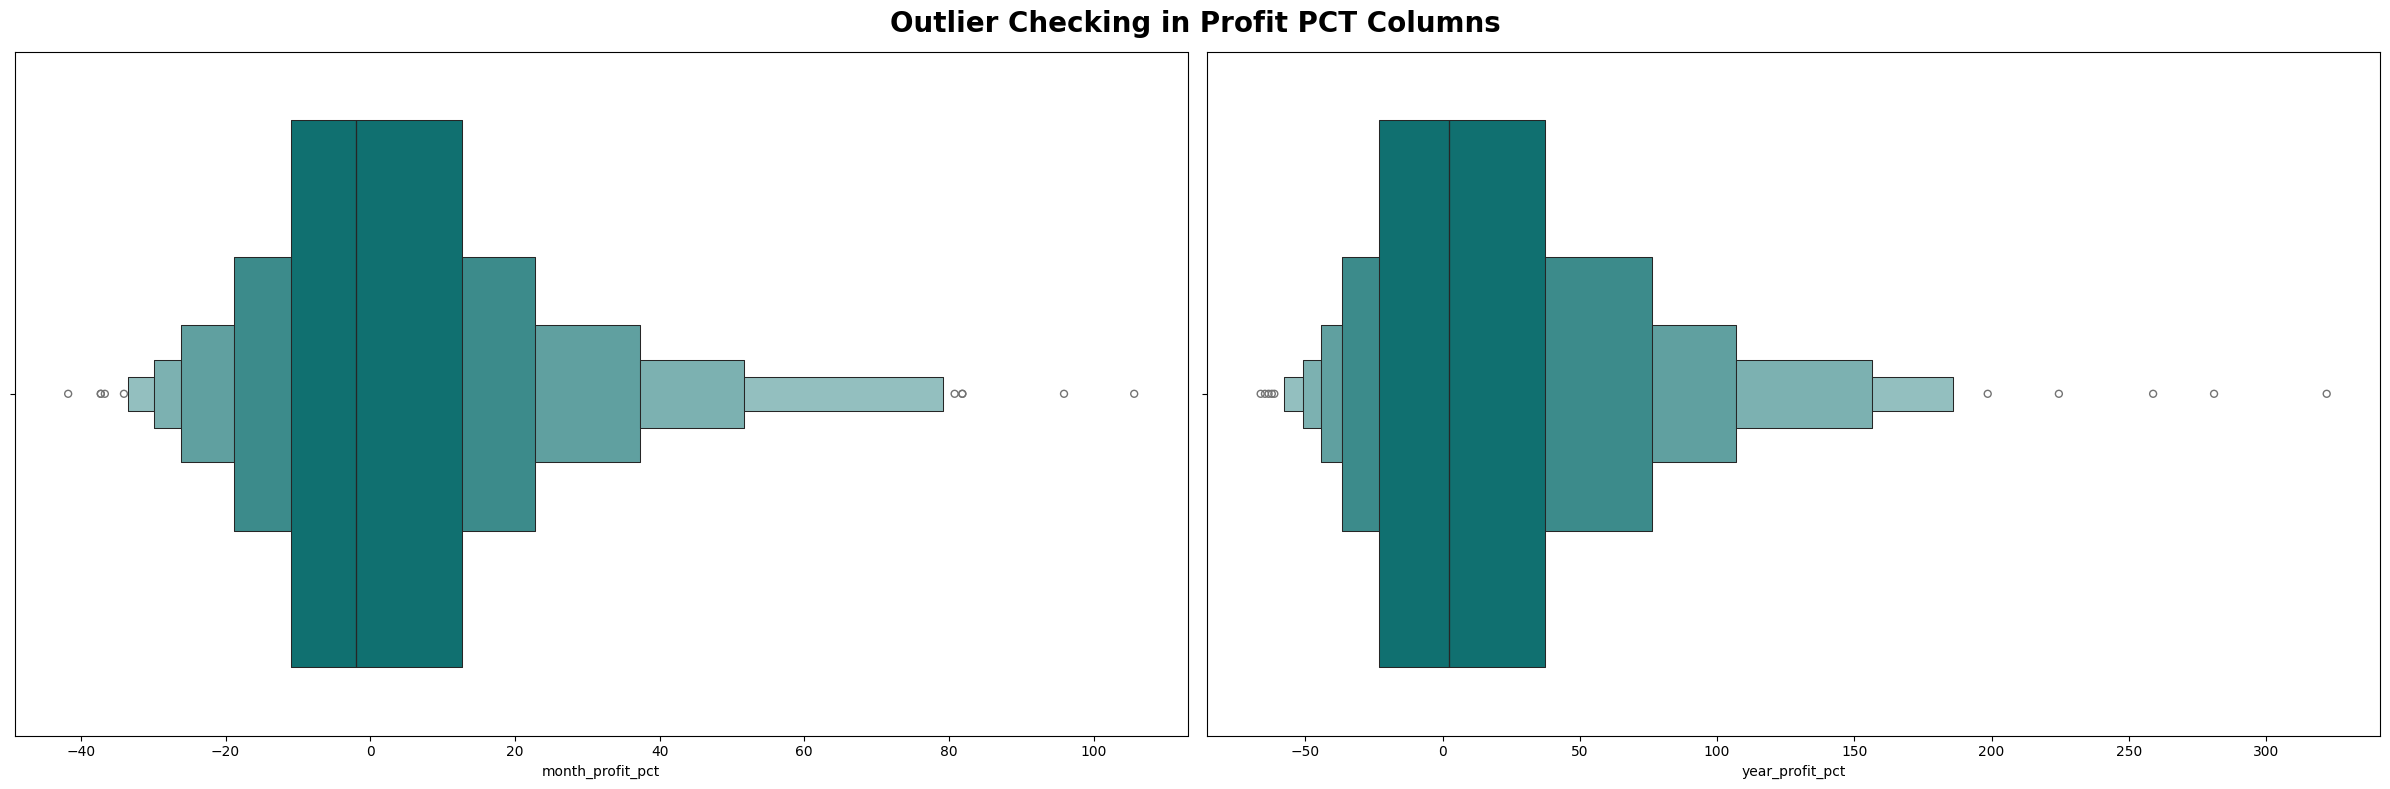

In [26]:
columns =['month_profit_pct', 'year_profit_pct']


fig, axes = plt.subplots(1,2, figsize= (24,8))
axes = axes.flatten()

for ax, col in zip(axes, columns):
    sns.boxenplot(x = col, data = data, color = "teal",ax = ax)
plt.suptitle("Outlier Checking in Profit PCT Columns",fontsize = 20, fontweight = 'bold')
plt.tight_layout()
plt.show()

In [43]:
cols = ['month_profit_pct', 'year_profit_pct']
data[cols].corr(method='spearman')

,month_profit_pct,year_profit_pct
month_profit_pct,1.000000,0.003477
year_profit_pct,0.003477,1.000000


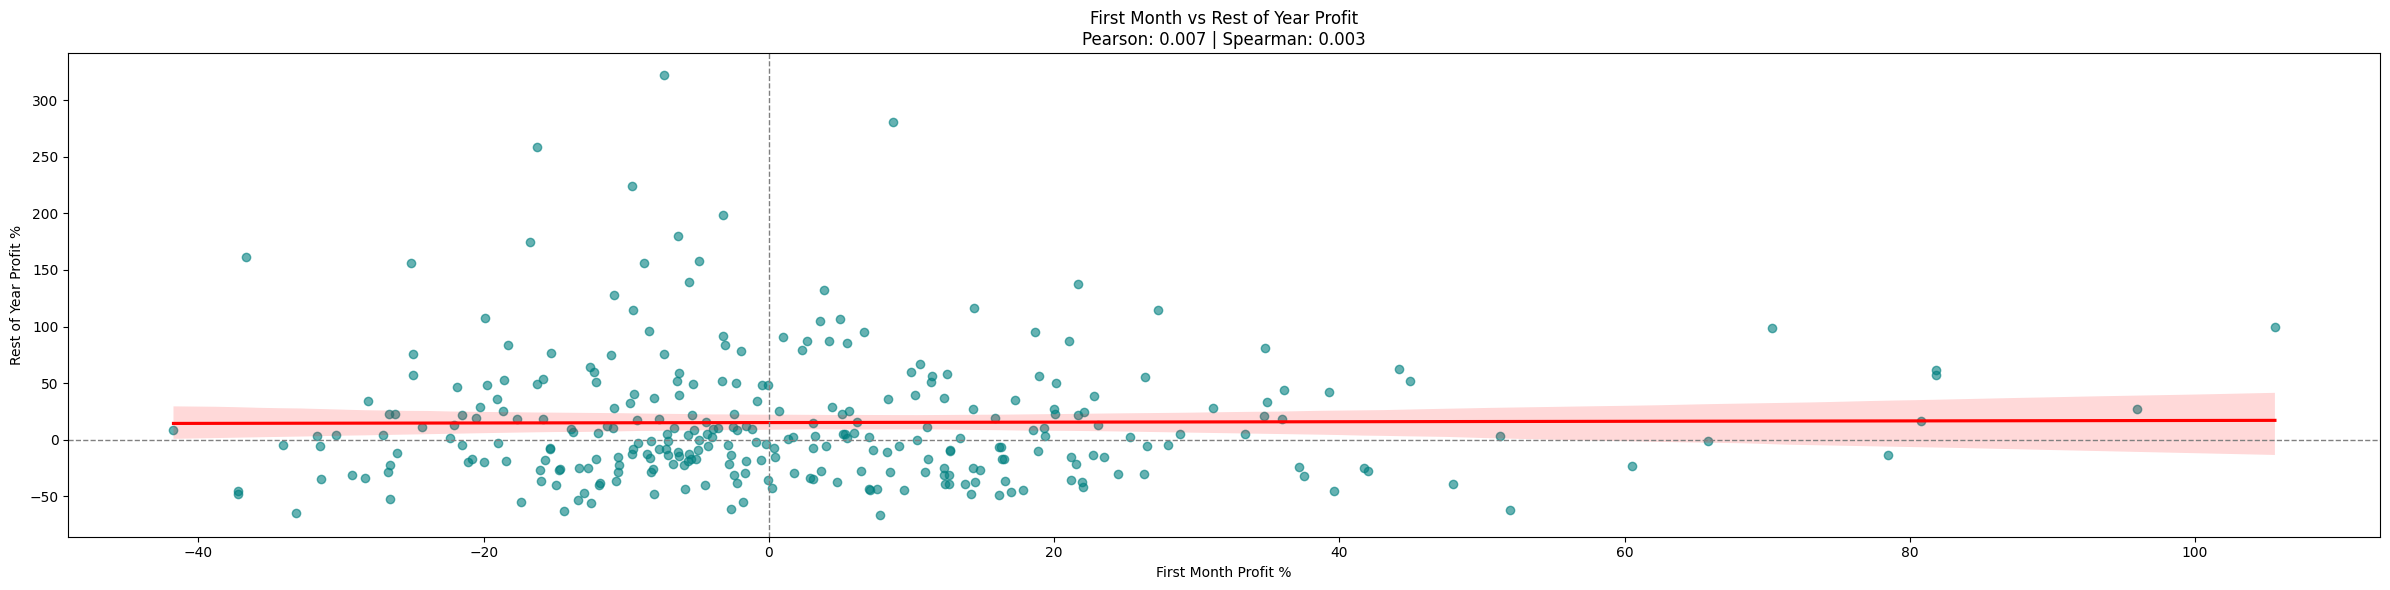

In [45]:
cols = ['month_profit_pct', 'year_profit_pct']

pearson = data[cols].corr(method='pearson').iloc[0, 1]
spearman = data[cols].corr(method='spearman').iloc[0, 1]

plt.figure(figsize=(24,6))
sns.regplot(x='month_profit_pct', y='year_profit_pct', data=data,
            scatter_kws={'alpha': 0.6, 'color': 'teal'},
            line_kws={'color': 'red'})

plt.axhline(0, color='grey', linestyle='--', linewidth=1)
plt.axvline(0, color='grey', linestyle='--', linewidth=1)

plt.title(f"First Month vs Rest of Year Profit\nPearson: {pearson:.3f} | Spearman: {spearman:.3f}")
plt.xlabel("First Month Profit %")
plt.ylabel("Rest of Year Profit %")
plt.tight_layout()
plt.show()

`There is no connection in first month profit and 1 year profit`